# 10 Block randomization of LOSO training

Main task: baseline, stress, amusement. Labels of entire episodes are reassigned within each training subject, preserving signal order and overlapping windows. The test set is not permuted. 1000 replicates, inner tuning re-run. The p-value is a conditional Monte Carlo diagnostic: it requires episode exchangeability in training, which is not guaranteed by the protocol. 

In [1]:
from pathlib import Path
import os,sys,json,copy
here=Path.cwd().resolve()
ROOT=next(p for p in [here,*here.parents] if (p/'configs/config.yaml').is_file())
os.chdir(ROOT)
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from src import workflow as w
from src.config import load
from src.provenance import verify_lock
from src.fusion import comparison_tables
from src.block_permutation import run
c=load();c=copy.deepcopy(verify_lock(w.root(c)/'protocol_lock.json')['config'])
SITE='wrist'
MODEL='logistic_regression'
frame=comparison_tables(w.load_tables(c),True)[SITE]
result,null=run(frame,c,model=MODEL,n_permutations=1000,seed=42,
    destination=w.root(c)/'results'/f'block_permutation_{SITE}_{MODEL}')
print(result)


Permutation 1/1000: BA=0.3589
Permutation 2/1000: BA=0.3452
Permutation 3/1000: BA=0.3262
Permutation 4/1000: BA=0.3701
Permutation 5/1000: BA=0.3120
Permutation 6/1000: BA=0.3946
Permutation 7/1000: BA=0.3326
Permutation 8/1000: BA=0.4175
Permutation 9/1000: BA=0.4106
Permutation 10/1000: BA=0.3463
Permutation 11/1000: BA=0.2886
Permutation 12/1000: BA=0.3544
Permutation 13/1000: BA=0.3762
Permutation 14/1000: BA=0.3477
Permutation 15/1000: BA=0.3770
Permutation 16/1000: BA=0.2187
Permutation 17/1000: BA=0.2541
Permutation 18/1000: BA=0.3096
Permutation 19/1000: BA=0.4274
Permutation 20/1000: BA=0.3402
Permutation 21/1000: BA=0.3202
Permutation 22/1000: BA=0.3148
Permutation 23/1000: BA=0.3481
Permutation 24/1000: BA=0.3387
Permutation 25/1000: BA=0.2123
Permutation 26/1000: BA=0.3510
Permutation 27/1000: BA=0.3124
Permutation 28/1000: BA=0.4045
Permutation 29/1000: BA=0.3143
Permutation 30/1000: BA=0.3025
Permutation 31/1000: BA=0.3761
Permutation 32/1000: BA=0.3226
Permutation 33/10

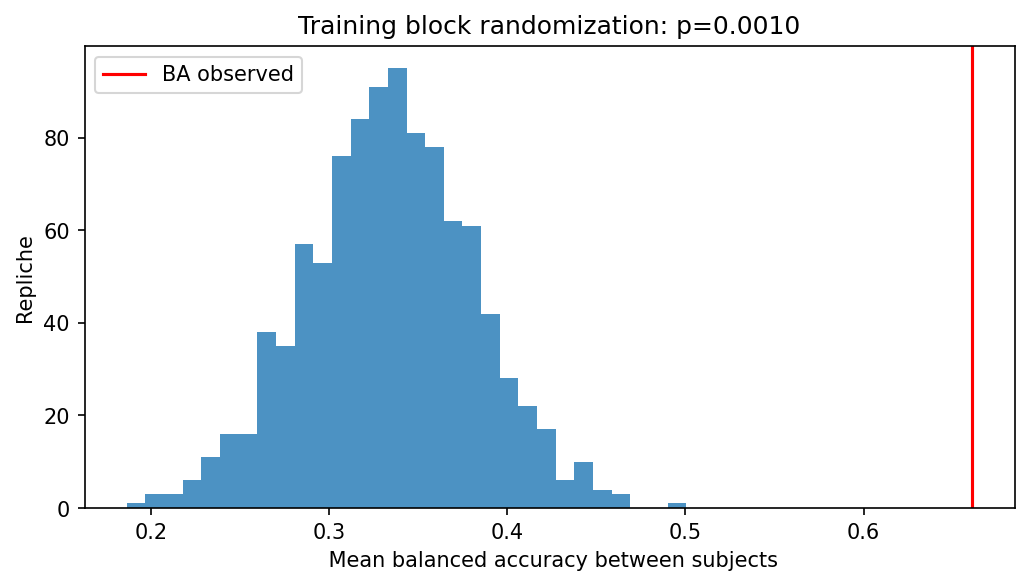

In [2]:
import matplotlib.pyplot as plt
from io import BytesIO
from IPython.display import display,Image
fig,ax=plt.subplots(figsize=(8,4))
ax.hist(null.balanced_accuracy,bins=30,alpha=.8)
ax.axvline(result['observed_BA'],color='red',label='BA observed')
ax.set(xlabel=' Mean balanced accuracy between subjects',ylabel='Repliche',title=f"Training block randomization: p={result['p_value']:.4f}")
ax.legend()
with BytesIO() as b:
    fig.savefig(b,format='png',dpi=150,bbox_inches='tight');data=b.getvalue()
plt.close(fig);display(Image(data=data))


## Interpretation of the training-block randomization analysis

### Scope and procedure

This analysis evaluates **wrist logistic regression** on the primary
baseline/stress/amusement task using LOSO balanced accuracy averaged
equally across participants.

The observed model is compared with **1,000 randomized training-label
replicates**. Each replicate repeats the outer LOSO evaluation and
inner hyperparameter tuning.

Within each outer fold:

- Labels are reassigned among whole temporal episodes within each
  training participant.
- All windows from an episode receive the same reassigned label.
- Signal order, episode boundaries, and overlapping-window structure
  remain unchanged.
- The held-out participant's labels are never permuted.

The procedure preserves the number of episodes assigned to each class
within participant. It does **not necessarily preserve window-level
class proportions**, because episodes contain different numbers of
available windows.

### Observed performance versus the randomized reference distribution

All **1,000 distinct replicate identifiers** are present in the saved
distribution.

| Statistic | Balanced accuracy |
|---|---:|
| Observed LOSO score | **66.11%** |
| Randomized-distribution mean | **33.38%** |
| Randomized-distribution standard deviation | 4.72 percentage points |
| Minimum randomized score | 18.63% |
| Maximum randomized score | **50.05%** |
| Randomized 2.5th percentile | 23.93% |
| Randomized 97.5th percentile | 42.61% |

The randomized mean is close to the three-class balanced-accuracy
reference of **33.33%**.

The observed score is approximately **32.73 percentage points above the
randomized mean** and exceeds every score obtained in the 1,000
randomized replicates.

The interval from 23.93% to 42.61% describes the central 95% of the
randomized scores. It is **not a confidence interval for observed
classification performance**.

No randomized replicate reached or exceeded the observed score:

**Exceedances: 0 out of 1,000.**

The one-sided Monte Carlo p-value uses the plus-one correction:

$$
p = \frac{1 + \#\{BA_{\mathrm{randomized}} \geq BA_{\mathrm{observed}}\}}{B + 1}
  = \frac{1}{1001}
  \approx 0.000999
$$

The result is reported as **p = 0.001**, not p = 0.

This is the smallest p-value that this calculation can return with
1,000 replicates. Zero exceedances do not imply that the underlying
tail probability is exactly zero.

### Interpretation

Under the implemented training-label randomization scheme, the observed
wrist logistic-regression performance is substantially higher than the
randomized reference scores.

The result supports the conclusion that the original training-label
assignment contains predictive information that is disrupted by
reassigning episode labels.

However, this interpretation is **conditional on the chosen randomization
scheme and its assumptions**. It is not an exact population-level test
of generalization.

### Exchangeability and dependence limitations

Preserving temporal blocks does not automatically establish that their
labels are exchangeable.

Experimental order, episode duration, condition-specific behavior, and
other recording differences may make some label reassignments
scientifically implausible. Reassignment also changes window-level class
proportions when episode lengths differ.

Furthermore:

- LOSO training sets overlap across held-out participants.
- Windows within recordings are temporally dependent.
- Test labels remain fixed throughout this conditional diagnostic.
- The null distribution reflects this particular training-label
  perturbation, not every possible definition of chance performance.

The p-value should therefore be presented as an **exploratory conditional
randomization result**, rather than an assumption-free significance claim.

### What this analysis does not establish

This result does not:

- Identify the best algorithm or sensor configuration.
- Demonstrate superiority over another fitted model.
- Validate late fusion, reduced-feature models, or other tasks.
- Establish clinical validity or everyday stress detection.
- Prove that predictive information is specific to subjective stress
  rather than other characteristics of the experimental conditions.

It applies specifically to the evaluated **wrist logistic-regression
three-class pipeline**.

### Conclusion

The observed mean LOSO balanced accuracy of **66.11%** exceeds all
1,000 training-block randomized scores, giving a corrected Monte Carlo
p-value of **0.001**.

This provides evidence of predictive structure relative to the implemented
randomization reference, while remaining conditional on episode-label
exchangeability and the limitations of the laboratory LOSO design.